MobileNetV2

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    GlobalAveragePooling2D
)

In [3]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_path = "../data/chest_xray/train"
test_path = "../data/chest_xray/test"

In [4]:
#TrainDataAugmentation
train_datagen = ImageDataGenerator(

    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    validation_split=0.2
)
#Test Preprocessing
test_datagen = ImageDataGenerator(
    rescale=1./255
)

In [5]:
# Train and Validation Generator
train_generator = train_datagen.flow_from_directory(

    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training"
)

val_generator = train_datagen.flow_from_directory(

    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation"
)

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.


MobileNetV2 Model 

In [6]:
#Pretrained Model
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
# Freeze pretrained MobileNetV2 layers
# so initially only custom pneumonia classification layers are trained.
# reduce overfitting,training time, computation.
base_model.trainable = False

In [8]:
#Building Model 
model = Sequential([

    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
#Compile
model.compile(

    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [10]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(

    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

Model Training 

In [11]:
#COMPUTation CLASS WEIGHTS

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weights = dict(
    enumerate(class_weights)
)
print(class_weights)

{0: np.float64(1.9445479962721341), 1: np.float64(0.6730645161290323)}


In [12]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stop]
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 156s 1s/step - accuracy: 0.8720 - loss: 0.2822 - val_accuracy: 0.9175 - val_loss: 0.1844
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 86s 655ms/step - accuracy: 0.9257 - loss: 0.1724 - val_accuracy: 0.9214 - val_loss: 0.1946
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 88s 673ms/step - accuracy: 0.9360 - loss: 0.1537 - val_accuracy: 0.9310 - val_loss: 0.1642
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 84s 643ms/step - accuracy: 0.9300 - loss: 0.1526 - val_accuracy: 0.9453 - val_loss: 0.1293
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 84s 642ms/step - accuracy: 0.9379 - loss: 0.1477 - val_accuracy: 0.9386 - val_loss: 0.1476
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 84s 643ms/step - accuracy: 0.9449 - loss: 0.1336 - val_accuracy: 0.9530 - val_loss: 0.1323
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 83s 633ms/step - accuracy: 0.9442 - loss: 0.1319 - val_accuracy: 0.9348 - val_loss: 0.1599


Evaluation 

In [13]:
#Test Accuracy

test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

test_loss, test_accuracy = model.evaluate(
    test_generator
)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

Found 624 images belonging to 2 classes.
20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 672ms/step - accuracy: 0.9054 - loss: 0.2231
Test Accuracy: 0.9054487347602844
Test Loss: 0.22308017313480377


In [14]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)
predictions = model.predict(
    test_generator
)
predicted_classes = (
    predictions > 0.5
).astype(int)


true_classes = test_generator.classes
print(
    classification_report(
        true_classes,
        predicted_classes
    )
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 459ms/step
              precision    recall  f1-score   support

           0       0.90      0.84      0.87       234
           1       0.91      0.95      0.93       390

    accuracy                           0.91       624
   macro avg       0.90      0.89      0.90       624
weighted avg       0.91      0.91      0.90       624



[[196  38]
 [ 21 369]]


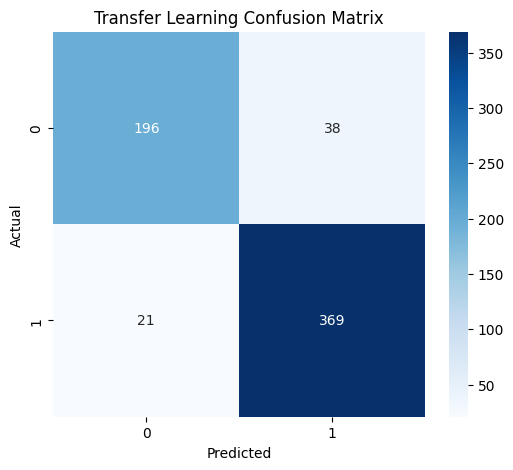

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    true_classes,
    predicted_classes
)

print(cm)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Transfer Learning Confusion Matrix")
plt.show()

In [16]:
model.save(
    "../models/pneumovision_transfer_model.h5"
)